# 02 — Lire Q, K, V et O : trouver le circuit de copie à partir des poids seuls

**Références · Weight-Space Programming** · durée conseillée : ~20 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/fr/references/01_weight_space_programming/02_reading_qk_ov_circuits.ipynb)

Dans l'expérience 3, Astra ne reçoit que les **blocs du milieu** d'un petit transformer au niveau caractère. Il n'a pas le droit de l'exécuter, et pourtant il désigne les têtes qui **copient** le texte précédent. Il y parvient en multipliant des matrices de poids entre elles, une méthode d'Elhage et al. (2021) que personne ne lui a montrée.

Ce notebook enseigne cette méthode sur un modèle assez petit pour tout vérifier. Il répond aussi à une question du chapitre 2 : **qu'apprennent vraiment les matrices Query, Key et Value ?**

**À la fin de ce notebook, vous saurez :**
1. Expliquer pourquoi `W_Q` et `W_K` ne comptent qu'à travers leur produit `W_QK = W_Qᵀ W_K`, et `W_V`, `W_O` à travers `W_OV = W_O W_V`.
2. Lire le **circuit OV** d'une tête (ce qu'elle déplace) et son **circuit QK** (où elle regarde) comme des tables sur les tokens et les positions.
3. Trouver, à partir des poids seuls, comment deux têtes de couches différentes se **composent** en un algorithme.
4. Confirmer cette lecture avec les motifs d'attention et des ablations (les vérifications qu'Astra n'avait *pas* le droit de faire).

**Plan :**
1. La tâche : copier un segment répété
2. Un transformer fait uniquement de têtes d'attention
3. L'entraînement, et un saut soudain
4. Les deux circuits d'une tête
5. Lire OV : qui copie ?
6. Lire QK : où regarde chaque tête ?
7. Composition : comment la couche 0 aide la couche 1
8. Vérifier avec une forward pass et des ablations
9. Retour au chapitre 2 : ce qu'apprennent Q, K, V
10. Bilan, questions, exercices

In [1]:
# Sur Google Colab : récupérer le dépôt du cours (wsp.py est à côté de ce notebook).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("wsp.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/fr/references/01_weight_space_programming

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import wsp
torch.manual_seed(0)
torch.set_grad_enabled(True)
VOCAB, D_MODEL, N_HEAD, N_LAYER, CTX = 48, 64, 4, 2, 48

## 1. La tâche : copier un segment répété

Chaque séquence compte 48 tokens aléatoires (tirés d'un vocabulaire de 48). Quelque part à l'intérieur, un segment aléatoire de 6 à 16 tokens est **répété** juste après lui-même, à une position aléatoire.

Des tokens aléatoires ne peuvent pas être prédits (meilleure loss = ln 48 ≈ 3,87). Mais une fois la répétition commencée, le token suivant **peut** être prédit en regardant en arrière : *« le token courant est déjà apparu ; ce qui l'a suivi la première fois va le suivre maintenant »*. Cette règle s'appelle l'**induction**. C'est la forme la plus simple d'apprentissage en contexte (*in-context learning*), et les modèles la réalisent en copiant.

Nous mesurons la loss **uniquement sur les positions prévisibles** (le `mask`).

In [3]:
x, y, mask, src = wsp.repeated_batch(1, VOCAB, CTX, torch.Generator().manual_seed(1))
print("tokens      :", x[0].tolist())
print("prévisibles :", "".join("^" if m else "." for m in mask[0].tolist()))
rep = torch.nonzero(src[0] >= 0).flatten()
print(f"les positions {rep[0].item()}..{rep[-1].item()} répètent les positions {src[0, rep[0]].item()}..{src[0, rep[-1]].item()}")

tokens      : [37, 11, 12, 8, 31, 25, 11, 5, 47, 0, 32, 33, 28, 23, 13, 12, 6, 9, 2, 4, 30, 21, 2, 5, 47, 0, 32, 33, 28, 23, 13, 12, 6, 9, 2, 4, 30, 21, 2, 38, 45, 41, 41, 23, 15, 45, 6, 9]
prévisibles : .......................^^^^^^^^^^^^^^^..........
les positions 23..38 répètent les positions 7..22


## 2. Un transformer fait uniquement de têtes d'attention

Pour que chaque calcul soit lisible, nous réduisons le mini-GPT du chapitre 2 à l'os :

- embedding de tokens `E` + **embedding de positions absolu appris** `P` (comme au chapitre 2) ;
- **2 couches d'attention × 4 têtes**, avec connexions résiduelles ;
- **ni MLP ni LayerNorm** : seules les têtes déplacent de l'information ;
- unembedding `U` → logits.

`wsp.AttnOnly` fait une quarantaine de lignes. Chaque couche stocke Q, K, V, O sous forme de quatre matrices `d×d`, et `head_weights(h)` découpe la part de la tête `h` (`hs = 64/4 = 16` dimensions).

In [4]:
model = wsp.AttnOnly(VOCAB, D_MODEL, N_HEAD, N_LAYER, CTX)
print(model)
print("paramètres :", sum(p.numel() for p in model.parameters()))

AttnOnly(
  (E): Embedding(48, 64)
  (P): Embedding(48, 64)
  (layers): ModuleList(
    (0-1): 2 x Attention(
      (q): Linear(in_features=64, out_features=64, bias=False)
      (k): Linear(in_features=64, out_features=64, bias=False)
      (v): Linear(in_features=64, out_features=64, bias=False)
      (o): Linear(in_features=64, out_features=64, bias=False)
    )
  )
  (U): Linear(in_features=64, out_features=48, bias=False)
)
paramètres : 41984


## 3. L'entraînement, et un saut soudain

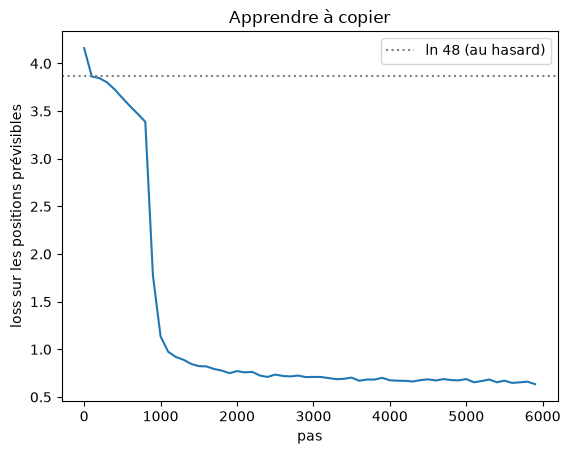

loss finale sur les positions prévisibles : 0.63


In [5]:
torch.manual_seed(0)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.01)
xv, yv, mv, sv = wsp.repeated_batch(512, VOCAB, CTX, torch.Generator().manual_seed(123))  # jeu d'évaluation fixe
curve = []
for it in range(6000):
    xb, yb = wsp.repeated_batch(64, VOCAB, CTX)[:2]
    logits, _ = model(xb)
    loss = F.cross_entropy(logits.reshape(-1, VOCAB), yb.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 100 == 0:
        curve.append((it, wsp.repeated_loss(model, xv, yv, mv)))
torch.set_grad_enabled(False)

plt.plot(*zip(*curve)); plt.axhline(3.87, ls=":", c="gray", label="ln 48 (au hasard)")
plt.xlabel("pas"); plt.ylabel("loss sur les positions prévisibles"); plt.legend(); plt.title("Apprendre à copier"); plt.show()
print(f"loss finale sur les positions prévisibles : {curve[-1][1]:.2f}")

La loss reste longtemps à plat près du niveau « au hasard », puis **chute brutalement**. Olsson et al. (2022) ont observé le même saut dans de vrais modèles de langage et l'ont relié à la formation de **têtes d'induction**. Un circuit qui demande la coopération de deux têtes ne sert à rien tant que les deux morceaux n'existent pas : il apparaît donc d'un coup.

Passons à la vraie question : **quelle tête fait quoi ?** Nous y répondons d'abord **à partir des poids seuls**, comme Astra dans l'expérience 3, et nous ne vérifions avec une forward pass qu'à la fin.

## 4. Les deux circuits d'une tête

Pour une position de requête $i$ et une position de clé $j$, une tête calcule

$$\text{score}(i,j) = (W_Q x_i)\cdot(W_K x_j) = x_i^\top \underbrace{W_Q^\top W_K}_{W_{QK}}\, x_j \qquad\qquad \text{out}_i = \sum_j \text{softmax}(\text{score})_{ij}\; \underbrace{W_O W_V}_{W_{OV}}\, x_j$$

Une tête est donc **deux programmes indépendants** :

| Circuit | Matrice | Décide |
|---|---|---|
| **QK** | $W_{QK}=W_Q^\top W_K$ ($d\times d$) | *où* regarder : quelles positions de clé reçoivent l'attention |
| **OV** | $W_{OV}=W_O W_V$ ($d\times d$) | *quoi* déplacer : ce qui est écrit dans le flux résiduel une fois l'attention fixée |

`W_Q` et `W_K` n'ont jamais de sens **seules**. On peut multiplier `W_Q` par n'importe quelle matrice inversible `A` et `W_K` par `A⁻ᵀ` sans changer le modèle. Seul le produit est réel. Même chose pour `W_V` et `W_O`.

Pour lire une matrice $d\times d$, nous la **prenons en sandwich** entre des objets que nous comprenons : les embeddings de tokens `E` (48×64), les embeddings de positions `P` (48×64) et l'unembedding `U` (48×64).

In [6]:
E, P, U = model.E.weight, model.P.weight, model.U.weight   # (48, 64) chacune

def circuits(layer, head):
    WQ, WK, WV, WO = model.layers[layer].head_weights(head)
    return WQ.T @ WK, WO @ WV          # W_QK (64x64), W_OV (64x64)

WQK, WOV = circuits(0, 0)
print("W_QK :", tuple(WQK.shape), "| W_OV :", tuple(WOV.shape))
print("rang de W_QK :", torch.linalg.matrix_rank(WQK).item(), "| rang de W_OV :", torch.linalg.matrix_rank(WOV).item(),
      "(au plus head_size = 16 : une tête lit et écrit une tranche de 16 dimensions)")

W_QK : (64, 64) | W_OV : (64, 64)
rang de W_QK : 16 | rang de W_OV : 16 (au plus head_size = 16 : une tête lit et écrit une tranche de 16 dimensions)


## 5. Lire OV : qui copie ?

$U\,W_{OV}\,E^\top$ est une table 48×48. L'entrée $(s,t)$ = *« si cette tête regarde le token $t$, de combien augmente-t-elle le logit du token $s$ ? »* Une **tête de copie** a une diagonale vive : regarder le token $t$ augmente $t$.

Un résumé en un nombre (Elhage et al.) est le **score de copie** $\sum_k \lambda_k / \sum_k |\lambda_k|$ sur les valeurs propres de cette table. Il vaut +1 pour une copie pure, −1 pour une anti-copie pure, et environ 0 pour une correspondance sans rapport.

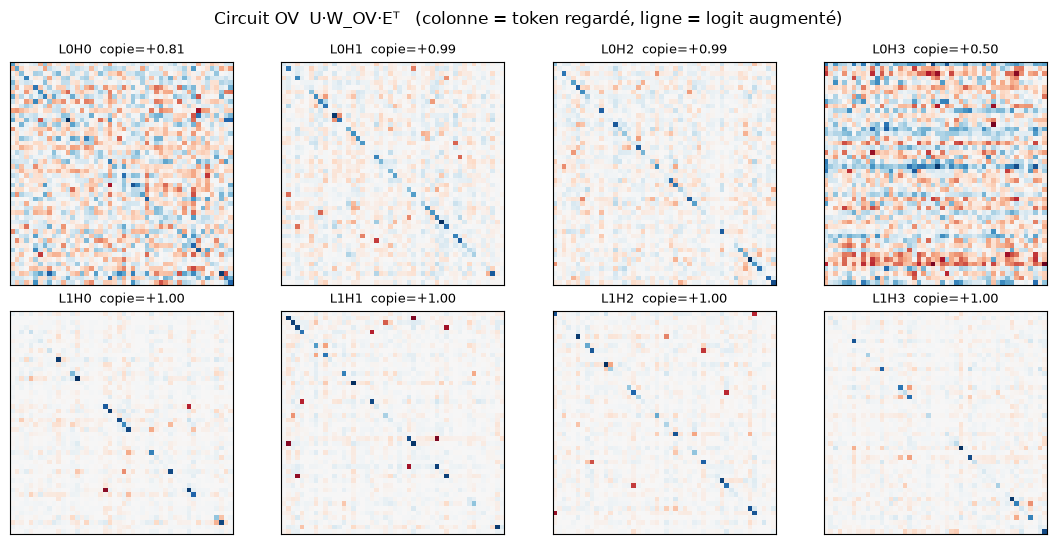

In [7]:
def ov_table(layer, head):
    return U @ circuits(layer, head)[1] @ E.T                 # (vocab, vocab)

def copying_score(M):
    ev = torch.linalg.eigvals(M)
    return (ev.sum().real / ev.abs().sum()).item()

fig, axes = plt.subplots(N_LAYER, N_HEAD, figsize=(11, 5.5))
for l in range(N_LAYER):
    for h in range(N_HEAD):
        M = ov_table(l, h)
        axes[l, h].imshow(M, cmap="RdBu", vmin=-M.abs().max(), vmax=M.abs().max())
        axes[l, h].set_title(f"L{l}H{h}  copie={copying_score(M):+.2f}", fontsize=9)
        axes[l, h].set_xticks([]); axes[l, h].set_yticks([])
fig.suptitle("Circuit OV  U·W_OV·Eᵀ   (colonne = token regardé, ligne = logit augmenté)")
plt.tight_layout(); plt.show()

Les quatre têtes de la **couche 1** ont une diagonale nette et un score de copie proche de +1 : **elles copient le token qu'elles regardent** directement dans les logits. Ce sont les têtes de copie que cherchait l'expérience 3.

Les tables OV de la couche 0 paraissent plus faibles. Attention : cela ne veut *pas* dire que la couche 0 ne fait rien. `U W_OV Eᵀ` ne mesure que les effets **sur les logits de sortie**. Une tête de la couche 0 peut écrire quelque chose destiné à être lu par la **couche 1**, pas par la sortie. Nous y revenons à la section 7.

## 6. Lire QK : où regarde chaque tête ?

Les scores d'attention mélangent deux types d'information dans $x_j = E[\text{token}_j] + P[j]$. Nous les lisons séparément :

- **token → token** : $E\,W_{QK}\,E^\top$. Une diagonale vive signifie « une requête regarde les clés qui portent **le même token** ».
- **position → position** : $P\,W_{QK}\,P^\top$, avec le masque causal. Une ligne vive juste sous la diagonale signifierait « regarder la position **précédente** ». C'est la *previous-token head* des manuels.

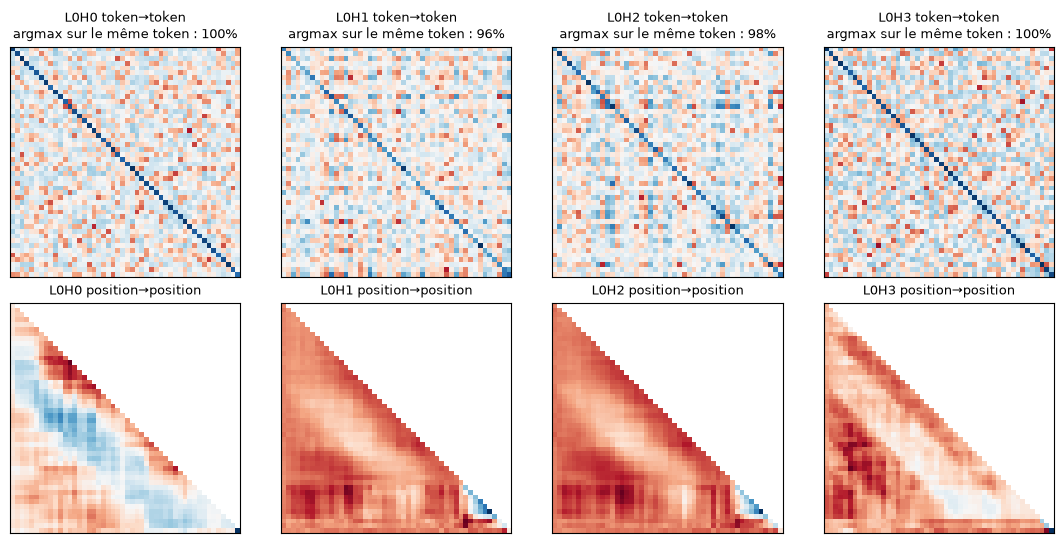

In [8]:
causal = torch.triu(torch.ones(CTX, CTX, dtype=torch.bool), 1)

def qk_token(layer, head):
    return E @ circuits(layer, head)[0] @ E.T

def qk_pos(layer, head):
    return (P @ circuits(layer, head)[0] @ P.T).masked_fill(causal, float("nan"))

fig, axes = plt.subplots(2, N_HEAD, figsize=(11, 5.5))
for h in range(N_HEAD):
    T_ = qk_token(0, h); Pm = qk_pos(0, h)
    dup = (T_.argmax(1) == torch.arange(VOCAB)).float().mean().item()
    axes[0, h].imshow(T_, cmap="RdBu", vmin=-T_.abs().max(), vmax=T_.abs().max())
    axes[0, h].set_title(f"L0H{h} token→token\nargmax sur le même token : {dup:.0%}", fontsize=9)
    axes[1, h].imshow(Pm, cmap="RdBu"); axes[1, h].set_title(f"L0H{h} position→position", fontsize=9)
    for a in axes[:, h]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Lisons les graphiques :

- **Token → token :** chaque tête de la couche 0 a une forte **diagonale**. Chacune est une **tête de token dupliqué** (*duplicate-token head*) : un token de requête cherche *ses propres occurrences antérieures*.
- **Position → position :** il n'y a **aucune** ligne vive sous la diagonale. Ce modèle n'a **pas** appris de previous-token head.

C'est une bonne leçon de lecture. Le circuit d'induction classique (Olsson et al.) est *previous-token head en couche 0 → tête d'induction en couche 1*. Notre modèle a trouvé **un autre algorithme**, qui marche tout aussi bien. Si nous avions supposé le circuit des manuels, nous l'aurions mal lu. **Lisez ce qui est là, pas ce que vous attendez.** (Avec une autre graine, vous obtiendrez peut-être la version des manuels. L'exercice 1 vous demande de vérifier.)

La couche 0 trouve donc *« où mon token est-il déjà apparu ? »*. Comment la couche 1 sait-elle ensuite *ce qui venait après* ?

## 7. Composition : comment la couche 0 aide la couche 1

Hypothèse : quand une tête de la couche 0 regarde la copie antérieure à la position $j$, son circuit OV **transporte l'embedding de position** $P[j]$ jusqu'à la position courante. Une tête de la couche 1 peut alors s'en servir comme **requête** : *« trouver la clé à la position $j+1$ »*, le token juste après la copie antérieure. L'OV de cette tête de la couche 1 le copie ensuite vers la sortie (section 5).

C'est la **Q-composition** : la sortie d'une tête de la couche 0 alimente le côté **requête** d'une tête de la couche 1. Nous pouvons la tester avec les poids seuls. La requête construite à partir d'une position transportée est $W_{OV}^{(0)} P[j]$, et la clé à la position $k$ contient $P[k]$ :

$$S_{jk} = \big(W_{OV}^{(0)}P[j]\big)^\top W_{QK}^{(1)}\, P[k]$$

Si l'hypothèse est juste, la ligne $j$ de $S$ culmine en $k=j+1$.

part des positions j où la tête de la couche 1 regarde j+1, via l'OV de chaque tête de la couche 0 :
        L1H0  L1H1  L1H2  L1H3
L0H0    55%   53%   55%   53%
L0H1     6%   11%    9%    9%
L0H2     2%    6%    4%    4%
L0H3    70%   72%   51%   70%


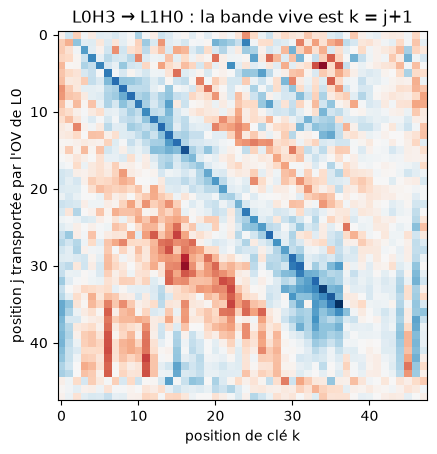

In [9]:
def q_composition(h0, h1):
    WOV0 = circuits(0, h0)[1]
    WQK1 = circuits(1, h1)[0]
    return (P @ WOV0.T) @ WQK1 @ P.T                     # S[j, k]

def plus_one_rate(S):
    return (S.argmax(1)[:-1] == torch.arange(1, CTX)).float().mean().item()

table = torch.tensor([[plus_one_rate(q_composition(h0, h1)) for h1 in range(N_HEAD)] for h0 in range(N_HEAD)])
print("part des positions j où la tête de la couche 1 regarde j+1, via l'OV de chaque tête de la couche 0 :")
print("        " + "  ".join(f"L1H{h}" for h in range(N_HEAD)))
for h0 in range(N_HEAD):
    print(f"L0H{h0}   " + "  ".join(f"{v:4.0%}" for v in table[h0]))

h0_star = int(table.mean(1).argmax())
S = q_composition(h0_star, 0)
plt.imshow(S, cmap="RdBu", vmin=-S.abs().max(), vmax=S.abs().max())
plt.xlabel("position de clé k"); plt.ylabel("position j transportée par l'OV de L0")
plt.title(f"L0H{h0_star} → L1H0 : la bande vive est k = j+1"); plt.show()

Une tête de la couche 0 se détache : à travers son circuit OV, le circuit QK de **chaque** tête de la couche 1 pointe vers $j+1$. Tout l'algorithme a maintenant été lu dans les poids :

1. **Couche 0, la tête de token dupliqué (QK) :** « trouver l'occurrence antérieure de mon token ».
2. **Couche 0, la même tête (OV) :** « rapporter sa **position** $j$ ».
3. **Couche 1 (QK, Q-composition) :** « regarder la position $j+1$ ».
4. **Couche 1 (OV, copie) :** « copier ce token vers la sortie ».

L'expérience 3 a fait cela sur un modèle de texte réel à 4 couches et 6 têtes, sans aucune forward pass, et sa liste de têtes de copie correspondait à la vérité terrain mesurée.

## 8. Vérifier avec une forward pass et des ablations

Astra n'avait pas le droit de faire cela dans l'expérience 3. Nous, si. Deux vérifications :

- **Motifs d'attention :** les têtes de la couche 1 doivent regarder `src + 1` (le token après la copie antérieure). La tête de token dupliqué doit regarder `src`.
- **Ablation :** mettre à zéro la sortie d'une tête et mesurer de combien la loss sur les positions prévisibles augmente. Une tête sur le chemin critique doit faire très mal.

In [10]:
logits, patterns = model(xv)
bi, ti = torch.nonzero(sv >= 0, as_tuple=True)
base = wsp.repeated_loss(model, xv, yv, mv)
print(f"loss sur les positions prévisibles : {base:.3f}\n")
print("tête    attn→src   attn→src+1   hausse de la loss après ablation")
for l in range(N_LAYER):
    for h in range(N_HEAD):
        pat = patterns[l][:, h]
        to_src = pat[bi, ti, sv[bi, ti]].mean().item()
        to_next = pat[bi, ti, (sv[bi, ti] + 1).clamp(max=CTX - 1)].mean().item()
        delta = wsp.repeated_loss(model, xv, yv, mv, ablate=(l, h)) - base
        print(f"L{l}H{h}    {to_src:7.2f}   {to_next:10.2f}   {delta:+8.3f}")

loss sur les positions prévisibles : 0.655

tête    attn→src   attn→src+1   hausse de la loss après ablation
L0H0       0.61         0.02     +1.096
L0H1       0.22         0.06     -0.050


L0H2       0.24         0.05     -0.047
L0H3       0.71         0.01     +1.413
L1H0       0.04         0.70     +0.702


L1H1       0.04         0.72     +0.761
L1H2       0.04         0.71     +0.725
L1H3       0.05         0.69     +0.518


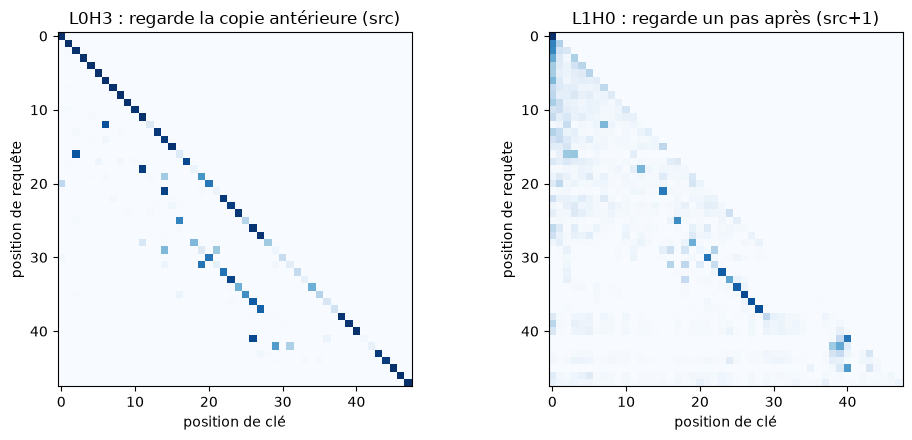

In [11]:
b = 0
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(patterns[0][b, h0_star], cmap="Blues"); axes[0].set_title(f"L0H{h0_star} : regarde la copie antérieure (src)")
axes[1].imshow(patterns[1][b, 0], cmap="Blues"); axes[1].set_title("L1H0 : regarde un pas après (src+1)")
for a in axes: a.set_xlabel("position de clé"); a.set_ylabel("position de requête")
plt.tight_layout(); plt.show()

La forward pass confirme la lecture des poids : la tête de token dupliqué regarde `src`, et les têtes de la couche 1 regardent `src + 1`. L'ablation de la tête de token dupliqué casse presque entièrement la copie. Les quatre têtes de la couche 1 se partagent le travail : en retirer une fait mal, mais moins.

> **Lien avec l'expérience 7.** Quand Astra devait trouver un Gemma-3 complaisant à partir des **poids seuls**, il a échoué 4 fois sur 4. Avec les **motifs d'attention** sur des textes qu'il avait écrits, il a réussi 3 fois sur 3, grâce à une tête (10.2) qui regarde la réponse suggérée par l'utilisateur au lieu de la question. Lire des poids est puissant sur de petits modèles propres comme celui-ci. Sur un vrai LLM, ce sont souvent les indices tirés d'une forward pass qui rendent la lecture fiable.

## 9. Retour au chapitre 2 : qu'apprennent Q, K et V ?

Au chapitre 2, nous avons dit : *requête = « ce que je cherche », clé = « ce que je contiens », valeur = « ce que je transmets »*. Ce notebook rend ces formules concrètes et vérifiables :

- **Q et K apprennent une *règle d'appariement*, et seulement en paire.** Ici, le $W_{QK}$ de la couche 0 a appris *« même token »* (une diagonale dans l'espace des tokens), et celui de la couche 1 *« position + 1 »* (une sur-diagonale dans l'espace des positions). La règle devient visible dès qu'on prend $W_{QK}$ en sandwich entre les embeddings.
- **V et O apprennent un *message*, eux aussi seulement en paire.** Le $W_{OV}$ de la couche 1 a appris *« copier le token »*. Celui de la couche 0 a appris *« envoyer ma position »*, un message destiné à une autre tête, pas à la sortie.
- **Les têtes se composent.** Le QK d'une tête peut utiliser ce que l'OV d'une tête précédente a écrit. C'est ainsi que deux opérations faibles deviennent un algorithme.

---
## 10. Bilan

- Une tête = un **circuit QK** (où regarder) + un **circuit OV** (quoi déplacer). Seuls les produits $W_Q^\top W_K$ et $W_O W_V$ comptent.
- Prenez-les en sandwich avec `E`, `P`, `U` pour les lire comme des tables sur les tokens et les positions. Le **score de copie** résume l'OV.
- Les têtes de couches différentes se **composent** (Q-, K- ou V-composition), et cette composition se lit aussi dans les poids.
- Les modèles entraînés peuvent trouver un **algorithme inattendu**. Lisez ce qui est là.

### Questions de vérification
1. Pourquoi ne peut-on pas interpréter `W_Q` seule ? Donnez la transformation qui change `W_Q` mais pas le modèle.
2. Une tête a un score de copie de −0,9. Que fait-elle aux logits des tokens qu'elle regarde ?
3. Pourquoi la loss reste-t-elle longtemps à plat avant de chuter brutalement ?
4. À la section 5, les tables OV de la couche 0 paraissaient faibles. Pourquoi était-il faux d'en conclure que la couche 0 est inutile ?

### Exercices
1. **Une autre graine.** Réentraînez avec `torch.manual_seed(1)` et `2`. Obtenez-vous toujours des têtes de token dupliqué, ou parfois une previous-token head (une ligne sous la diagonale dans `P W_QK Pᵀ`) ? Écrivez une fonction qui classe automatiquement chaque tête de la couche 0.
2. **Forcer le circuit des manuels.** Retirez l'embedding de position du chemin **valeur** seulement (donnez `E[token]` à `W_V` mais `E + P` à `W_Q`, `W_K`). L'astuce du token dupliqué ne peut plus transporter de positions. Qu'apprend le modèle à la place ?
3. **K-composition.** Écrivez le score de K-composition $\lVert W_{QK}^{(1)}\,W_{OV}^{(0)}\rVert_F / (\lVert W_{QK}^{(1)}\rVert_F\,\lVert W_{OV}^{(0)}\rVert_F)$ pour chaque paire. Trouve-t-il le circuit ici ? Pourquoi ?
4. **Le modèle du chapitre 2.** Chargez le mini-GPT entraîné dans `chapitre_2/09` et calculez le score de copie de chaque tête (`U W_O W_V Eᵀ` demande de la prudence : il y a une LayerNorm avant `lm_head` et un MLP entre les blocs). Quelles têtes copient ?

### Références
- N. Elhage et al., *A Mathematical Framework for Transformer Circuits* (2021) : <https://transformer-circuits.pub/2021/framework/index.html>
- C. Olsson et al., *In-context Learning and Induction Heads* (2022) : <https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html>
- Journaux de l'expérience 3 : `exp3_language/` dans <https://github.com/RikiyaT/lm_understand-logs> (le code Python d'Astra pour trouver les têtes de copie est dans `runs/*/tool_calls.jsonl`).